# Does Climate Shape Romantic Love? Predicting Cross-Cultural Intimacy, Passion, and Commitment from National Thermal Profile

**Data sources**
1. Kowal et al. (2025), *Cross-cultural data on romantic love and mate preferences from 117,293 participants across 175 countries*,
   `Final_dataset.csv` (OSF: https://doi.org/10.17605/osf.io/K54FX)
2. Berkeley Earth via Kaggle, `GlobalLandTemperaturesByCity.csv`, monthly average land temperature by city

## 1. Setup and imports

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import country_converter as coco
from scipy import stats

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)

RANDOM_STATE = 42

_cc = coco.CountryConverter()

def map_to_iso3(names):
    sentinel = "___NOT_FOUND___"
    results = _cc.convert(names=list(names), to="ISO3", not_found=sentinel)
    return [None if r == sentinel else r for r in results]

## 2. Configuration

In [22]:
SURVEY_DATA_PATH = "./dataset/Final_dataset.csv"                    # Dataset 1: cross-cultural data on romantic love
CLIMATE_DATA_PATH = "./dataset/GlobalLandTemperaturesByCity.csv"    # Dataset 2: Berkeley Earth, city level

MIN_PARTICIPANTS_PER_COUNTRY = 30     # countries with fewer respondents are dropped

CLIMATOLOGY_START_YEAR = 1991         # temperatures are averaged over these years
CLIMATOLOGY_END_YEAR = 2012

# The 15 items of the short Triangular Love Scale, each answered 1-5 (items 1-5 Intimacy, 6-10 Passion, 11-15 Commitment)
LOVE_ITEMS = [f"Love_{i}" for i in range(1, 16)]
LOVE_SCORES = ["Intimacy", "Passion", "Commitment"]   # computed by the dataset authors as the mean of five items each
ITEM_NAME = {
    "Love_1": "Warm_relationship", "Love_2": "Emotional_support", "Love_3": "Value_partner", "Love_4": "Comfortable",
    "Love_5": "Understands_me", "Love_6": "Very_romantic", "Love_7": "Attractive", "Love_8": "No_one_else_as_happy",
    "Love_9": "Magical", "Love_10": "Passionate", "Love_11": "Stability", "Love_12": "Solid_commitment",
    "Love_13": "Certain_of_love", "Love_14": "Permanent", "Love_15": "Responsibility",
}
ITEM_SUBSCALE = {f"Love_{i}": LOVE_SCORES[(i - 1) // 5] for i in range(1, 16)}
ITEM_LABEL = {item: f"{item.split('_')[1]}. {name.replace('_', ' ').lower()}" for item, name in ITEM_NAME.items()}

## 3. Load the survey data and filter respondents

Keep respondents who say they are currently in love and have all three love scores.

In [23]:
df = pd.read_csv(SURVEY_DATA_PATH, sep=";", encoding="utf-8", encoding_errors="replace", low_memory=False)
df = df[["Country_raised", "Love_currently"] + LOVE_SCORES + LOVE_ITEMS].copy()

for c in LOVE_ITEMS:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df[df["Love_currently"] == 1]          # 1 = "Yes" in the codebook
df = df.dropna(subset=LOVE_SCORES)

print(f"Respondents kept: {len(df):,}")
df.head()

Respondents kept: 46,408


,Country_raised,Love_currently,Intimacy,Passion,Commitment,Love_1,Love_2,Love_3,Love_4,Love_5,Love_6,Love_7,Love_8,Love_9,Love_10,Love_11,Love_12,Love_13,Love_14,Love_15
3,Nigeria,1.0,3.4,3.4,3.8,4.0,2.0,4.0,4.0,3.0,4.0,4.0,3.0,3.0,3.0,3.0,4.0,4.0,3.0,5.0
6,Nigeria,1.0,3.2,3.0,3.0,3.0,3.0,4.0,3.0,3.0,3.0,3.0,3.0,3.0,NaN,3.0,3.0,3.0,NaN,NaN
10,Nigeria,1.0,3.4,3.0,3.0,3.0,4.0,5.0,3.0,2.0,3.0,4.0,3.0,2.0,3.0,3.0,2.0,3.0,3.0,4.0
11,Nigeria,1.0,2.6,2.6,3.2,3.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,2.0,3.0,2.0,3.0,4.0,3.0,4.0
12,Nigeria,1.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0


## 4. Aggregate to country level

One row per country: the mean of each love score and item, and the number of respondents.

In [24]:
agg_spec = {c: (c, "mean") for c in LOVE_SCORES + LOVE_ITEMS}
agg_spec["n_participants"] = ("Intimacy", "size")

country_df = df.groupby("Country_raised").agg(**agg_spec).reset_index()
country_df = country_df[country_df["n_participants"] >= MIN_PARTICIPANTS_PER_COUNTRY]

country_df["iso3"] = map_to_iso3(country_df["Country_raised"])
print(f"Countries with at least {MIN_PARTICIPANTS_PER_COUNTRY} respondents: {len(country_df)}")
print("Country names without an ISO3 code:", sorted(country_df[country_df["iso3"].isna()]["Country_raised"]))
country_df = country_df.dropna(subset=["iso3"])
country_df.sort_values("n_participants", ascending=False).head(10)

Countries with at least 30 respondents: 81
Country names without an ISO3 code: []


,Country_raised,Intimacy,Passion,Commitment,Love_1,Love_2,Love_3,Love_4,Love_5,Love_6,Love_7,Love_8,Love_9,Love_10,Love_11,Love_12,Love_13,Love_14,Love_15,n_participants,iso3
150,Turkey,4.339027,3.981779,4.337224,4.443716,4.366238,4.577924,4.289515,4.034773,3.714323,4.366271,3.922366,3.771489,4.156391,4.278554,4.396830,4.305130,4.235341,4.499868,3817,TUR
118,Poland,4.500791,4.078151,4.490527,4.689182,4.384127,4.725760,4.545214,4.174860,3.754386,4.505160,4.264055,4.029121,3.852169,4.286590,4.499602,4.557590,4.485904,4.650079,3795,POL
72,Italy,4.349391,3.940464,4.417539,4.581524,4.292961,4.612703,4.276684,3.990674,3.645877,4.293223,4.012829,3.811544,3.953883,4.247834,4.532710,4.432330,4.454483,4.442368,2903,ITA
154,USA,4.484610,4.067275,4.514402,4.511141,4.379065,4.691485,4.592246,4.255804,3.895675,4.454059,4.155565,3.875335,3.961641,4.406863,4.566652,4.586453,4.453815,4.560856,2245,USA
99,Morocco,3.657410,3.536391,3.551736,3.974656,3.571350,3.604959,3.547960,3.589857,3.542999,3.563636,3.534435,3.541047,3.500826,3.554270,3.568595,3.585675,3.477135,3.573003,1815,MAR
122,Russia,4.360175,4.005339,4.533944,4.395128,4.262626,4.625370,4.411660,4.138013,3.722354,4.591340,4.188915,3.675870,3.863227,4.366726,4.553571,4.542534,4.634364,4.594065,1692,RUS
33,Chile,4.393190,3.793874,4.341965,4.416170,4.358940,4.641060,4.543103,4.008621,3.589488,4.416335,3.567333,3.504342,3.890365,4.365691,4.387268,4.545817,3.980040,4.436713,1510,CHL
53,France,4.226613,3.704030,4.170648,4.415081,4.093520,4.535398,4.269713,3.842066,3.328391,4.351770,3.652954,3.566165,3.639491,4.035477,4.355982,4.373797,4.013383,4.106273,1369,FRA
156,Ukraine,4.410487,4.050167,4.483486,4.597070,4.188300,4.709707,4.440073,4.125000,3.682320,4.564620,4.134986,3.835032,4.047750,4.279412,4.517431,4.528440,4.477502,4.630375,1095,UKR
38,Croatia,4.572934,4.258922,4.560949,4.611321,4.493862,4.762760,4.734153,4.273415,3.996209,4.635417,4.236967,4.180437,4.254028,4.508042,4.636537,4.602467,4.437618,4.634816,1061,HRV


## 5. City-based temperatures


In [25]:
# Chunked because the file is too large..
chunks = []
for chunk in pd.read_csv(CLIMATE_DATA_PATH, usecols=["dt", "AverageTemperature", "City", "Country", "Latitude", "Longitude"],
                         chunksize=1_000_000, encoding="utf-8"):
    year = chunk["dt"].str[:4].astype(int)
    chunk = chunk[(year >= CLIMATOLOGY_START_YEAR) & (year <= CLIMATOLOGY_END_YEAR)].dropna(subset=["AverageTemperature"])
    chunks.append(chunk)
city_temps = pd.concat(chunks, ignore_index=True)
city_temps["month"] = city_temps["dt"].str[5:7].astype(int)

CITY_KEY = ["Country", "City", "Latitude", "Longitude"]      # some city names repeat, so coordinates are part of the key
print(f"Rows in {CLIMATOLOGY_START_YEAR}-{CLIMATOLOGY_END_YEAR}: {len(city_temps):,} | "
      f"cities: {city_temps.groupby(CITY_KEY).ngroups:,} | countries: {city_temps['Country'].nunique()}")

Rows in 1991-2012: 926,640 | cities: 3,510 | countries: 159


In [26]:
# cities without all 12 months are dropped
city_monthly = city_temps.groupby(CITY_KEY + ["month"])["AverageTemperature"].mean().reset_index()
city_monthly = city_monthly[city_monthly.groupby(CITY_KEY)["month"].transform("nunique") == 12]

name_to_iso3 = city_monthly[["Country"]].drop_duplicates()
name_to_iso3["iso3"] = map_to_iso3(name_to_iso3["Country"])
print("City-file country names without an ISO3 code:", sorted(name_to_iso3[name_to_iso3["iso3"].isna()]["Country"]))
city_monthly = city_monthly.merge(name_to_iso3.dropna(subset=["iso3"]), on="Country")

# take the coldest and the hottest month
country_monthly = city_monthly.groupby(["iso3", "month"])["AverageTemperature"].mean().unstack("month")
climate_df = pd.DataFrame({
    "coldest_month_temp": country_monthly.min(axis=1),
    "hottest_month_temp": country_monthly.max(axis=1),
    "n_cities": city_monthly.drop_duplicates(["iso3", "City", "Latitude", "Longitude"]).groupby("iso3").size(),
}).reset_index()
print(f"Countries with temperature features: {len(climate_df)}")
climate_df.sort_values("n_cities", ascending=False).head()

City-file country names without an ISO3 code: []
Countries with temperature features: 159


,iso3,coldest_month_temp,hottest_month_temp,n_cities
66,IND,18.792961,31.821425,391
26,CHN,-0.731857,25.757402,380
151,USA,5.058601,24.902300,257
20,BRA,20.026995,25.047767,220
75,JPN,3.233349,25.804239,175


## 6. Merge survey and climate data

In [27]:
no_city = sorted(country_df[~country_df["iso3"].isin(climate_df["iso3"])]["Country_raised"])
print(f"Countries without any city in the temperature file dropped: {no_city}")

analysis_df = country_df.merge(climate_df, on="iso3", how="inner").reset_index(drop=True)
print(f"Countries in the analysis: {len(analysis_df)}")

Countries without any city in the temperature file dropped: ['Brunei', 'Kuwait']
Countries in the analysis: 79


## 7. Features and score-level targets

**Features:** `coldest_month_temp` and `hottest_month_temp`

**Score-level targets:** `Raw scores` and `Relative scores` 

In [28]:
for s in LOVE_SCORES:
    others = [x for x in LOVE_SCORES if x != s]
    analysis_df[f"{s}_relative"] = analysis_df[s] - analysis_df[others].mean(axis=1)
RELATIVE_SCORES = [f"{s}_relative" for s in LOVE_SCORES]

FEATURES = ["coldest_month_temp", "hottest_month_temp"]
print(f"Data points: {len(analysis_df)} countries | features: {FEATURES}")
analysis_df[FEATURES + LOVE_SCORES + RELATIVE_SCORES].describe().T[["count", "mean", "std", "min", "max"]].round(3)

Data points: 79 countries | features: ['coldest_month_temp', 'hottest_month_temp']


,count,mean,std,min,max
coldest_month_temp,79.0,7.956,10.208,-12.162,26.379
hottest_month_temp,79.0,23.084,4.420,13.619,33.951
Intimacy,79.0,4.369,0.189,3.540,4.786
Passion,79.0,3.975,0.207,3.505,4.801
Commitment,79.0,4.360,0.217,3.552,4.833
Intimacy_relative,79.0,0.202,0.101,-0.037,0.455
Passion_relative,79.0,-0.390,0.155,-0.693,0.007
Commitment_relative,79.0,0.188,0.117,-0.159,0.441


## 8. Train / test split

20% of the countries are held out as the test set. Chosen randomly with seed 42. 

In [29]:
TEST_COUNTRIES = ["ALB", "AUS", "BRA", "CAN", "CZE", "EGY", "DEU", "GRC", "GTM", "HUN", "IRN", "LTU", "MAR", "SWE", "CHE", "THA"]

missing = sorted(set(TEST_COUNTRIES) - set(analysis_df["iso3"]))
assert not missing, f"Test countries missing from the data: {missing}"

is_test = analysis_df["iso3"].isin(TEST_COUNTRIES)
train_df = analysis_df[~is_test].reset_index(drop=True)
print(f"Training / validation: {(~is_test).sum()} countries | test: {is_test.sum()} countries ({is_test.mean():.0%})")
print("Test countries:", ", ".join(sorted(analysis_df.loc[is_test, "Country_raised"])))

Training / validation: 63 countries | test: 16 countries (20%)
Test countries: Albania, Australia, Brazil, Canada, Czech Republic, Egypt, Germany, Greece, Guatemala, Hungary, Iran, Lithuania, Morocco, Sweden, Switzerland, Thailand


## 9. Target item selection

The three scores are each the mean of five items. Modelling all 15 items separately would add 15 targets, so this section checks
whether that is worthwhile. 

**How strongly is each item related to temperature**

An item counts as related to temperature if at least one of its two correlations (coldest or hottest month) has p < 0.05.

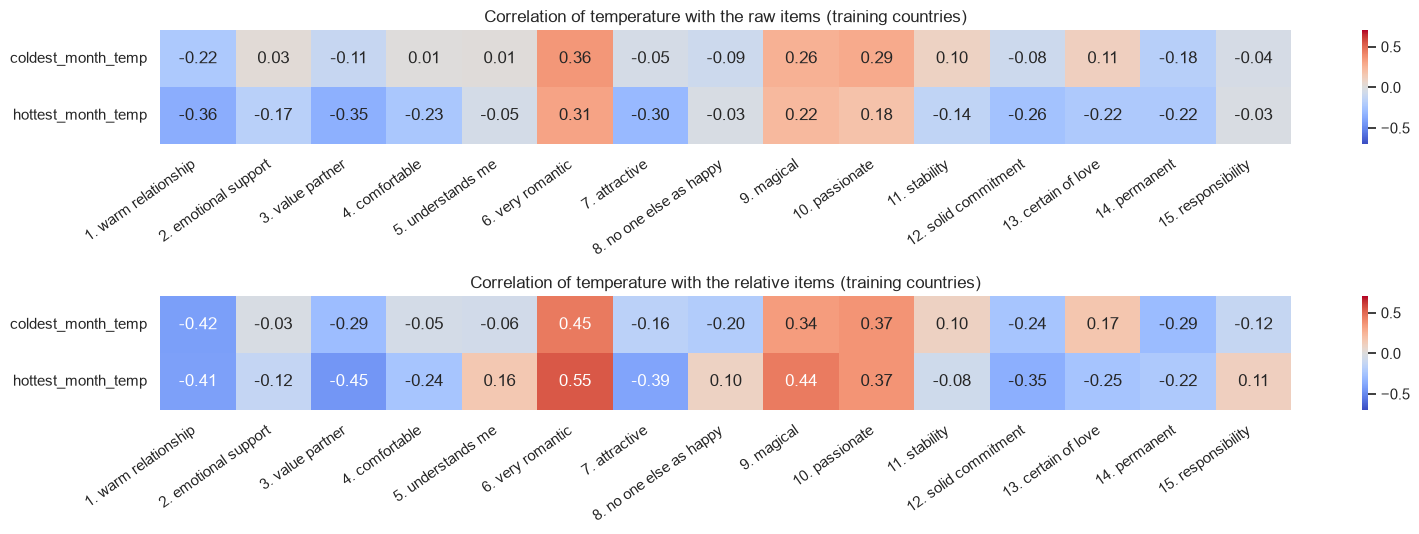

60 tests | screening threshold p < 0.05 | Bonferroni threshold p < 0.00083

Raw items with p < 0.05: 7 of 15 -> ['1. warm relationship', '3. value partner', '6. very romantic', '7. attractive', '9. magical', '10. passionate', '12. solid commitment']
Raw items passing Bonferroni: 0 of 15 -> []

Relative items with p < 0.05: 8 of 15 -> ['1. warm relationship', '3. value partner', '6. very romantic', '7. attractive', '9. magical', '10. passionate', '12. solid commitment', '14. permanent']
Relative items passing Bonferroni: 4 of 15 -> ['1. warm relationship', '3. value partner', '6. very romantic', '9. magical']


,label,score,r_raw_coldest,p_raw_coldest,r_relative_coldest,p_relative_coldest,r_raw_hottest,p_raw_hottest,r_relative_hottest,p_relative_hottest,raw_p<0.05,raw_p<bonferroni,relative_p<0.05,relative_p<bonferroni
item,,,,,,,,,,,,,,
Love_6,6. very romantic,Passion,0.3576,0.0040,0.4518,0.0002,0.3149,0.0119,0.5459,0.0000,True,False,True,True
Love_3,3. value partner,Intimacy,-0.1142,0.3728,-0.2866,0.0227,-0.3461,0.0055,-0.4485,0.0002,True,False,True,True
Love_9,9. magical,Passion,0.2623,0.0378,0.3403,0.0064,0.2244,0.0771,0.4440,0.0003,True,False,True,True
Love_1,1. warm relationship,Intimacy,-0.2195,0.0839,-0.4193,0.0006,-0.3599,0.0038,-0.4106,0.0008,True,False,True,True
Love_7,7. attractive,Passion,-0.0479,0.7093,-0.1639,0.1994,-0.3024,0.0160,-0.3950,0.0014,True,False,True,False
Love_10,10. passionate,Passion,0.2886,0.0218,0.3704,0.0028,0.1830,0.1511,0.3701,0.0028,True,False,True,False
Love_12,12. solid commitment,Commitment,-0.0822,0.5217,-0.2447,0.0532,-0.2593,0.0402,-0.3544,0.0044,True,False,True,False
Love_14,14. permanent,Commitment,-0.1764,0.1666,-0.2913,0.0205,-0.2168,0.0879,-0.2166,0.0882,False,False,True,False
Love_13,13. certain of love,Commitment,0.1136,0.3754,0.1676,0.1892,-0.2163,0.0886,-0.2472,0.0508,False,False,False,False


In [30]:
item_relative = train_df[LOVE_ITEMS].sub(train_df[LOVE_ITEMS].mean(axis=1), axis=0)

rows = []
for item in LOVE_ITEMS:
    row = {"item": item, "label": ITEM_LABEL[item], "score": ITEM_SUBSCALE[item]}
    for feat in FEATURES:
        short = feat.replace("_month_temp", "")
        row[f"r_raw_{short}"], row[f"p_raw_{short}"] = stats.pearsonr(train_df[feat], train_df[item])
        row[f"r_relative_{short}"], row[f"p_relative_{short}"] = stats.pearsonr(train_df[feat], item_relative[item])
    rows.append(row)
item_screen = pd.DataFrame(rows).set_index("item")

fig, axes = plt.subplots(2, 1, figsize=(16, 5.5))
for ax, form in zip(axes, ["raw", "relative"]):
    mat = item_screen[[f"r_{form}_coldest", f"r_{form}_hottest"]].T
    mat.index = FEATURES; mat.columns = [ITEM_LABEL[i] for i in LOVE_ITEMS]
    sns.heatmap(mat, annot=True, cmap="coolwarm", center=0, vmin=-0.7, vmax=0.7, fmt=".2f", ax=ax)
    ax.set_title(f"Correlation of temperature with the {form} items (training countries)")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
plt.savefig("fig_item_temperature_correlations.png", dpi=200)
plt.show()

ALPHA = 0.05                                               # screening threshold
N_ITEM_TESTS = len(LOVE_ITEMS) * len(FEATURES) * 2
BONFERRONI = ALPHA / N_ITEM_TESTS                          # stricter threshold, for comparison

for form in ["raw", "relative"]:
    p_min = item_screen[[f"p_{form}_coldest", f"p_{form}_hottest"]].min(axis=1)      # the smaller of the item's two p-values
    item_screen[f"{form}_p<0.05"] = p_min < ALPHA
    item_screen[f"{form}_p<bonferroni"] = p_min < BONFERRONI

print(f"{N_ITEM_TESTS} tests | screening threshold p < {ALPHA} | Bonferroni threshold p < {BONFERRONI:.5f}")
for form in ["raw", "relative"]:
    loose = [ITEM_LABEL[i] for i in LOVE_ITEMS if item_screen.loc[i, f"{form}_p<0.05"]]
    strict = [ITEM_LABEL[i] for i in LOVE_ITEMS if item_screen.loc[i, f"{form}_p<bonferroni"]]
    print(f"\n{form.capitalize()} items with p < {ALPHA}: {len(loose)} of 15 -> {loose}")
    print(f"{form.capitalize()} items passing Bonferroni: {len(strict)} of 15 -> {strict}")

strongest = item_screen[["r_relative_coldest", "r_relative_hottest"]].abs().max(axis=1)
item_screen.loc[strongest.sort_values(ascending=False).index].round(4)

**Final Decision**

Every **relative** item that passes the screening (p < 0.05 with at least one temperature feature, on the training countries)
is carried forward as an additional target. Items that fail the screening are dropped, because there is no sign that temperature
is related to them.


In [31]:
strength = item_screen[["r_relative_coldest", "r_relative_hottest"]].abs().max(axis=1)
selected_items = [i for i in strength.sort_values(ascending=False).index if item_screen.loc[i, "relative_p<0.05"]]
dropped_items = [i for i in LOVE_ITEMS if i not in selected_items]

ITEM_TARGETS = []
for item in selected_items:
    name = f"{ITEM_NAME[item]}_relative"
    analysis_df[name] = analysis_df[item] - analysis_df[LOVE_ITEMS].mean(axis=1)
    ITEM_TARGETS.append(name)

print(f"Relative items carried forward ({len(selected_items)}), strongest first:")
print(item_screen.loc[selected_items, ["label", "score", "r_relative_coldest", "p_relative_coldest",
                                       "r_relative_hottest", "p_relative_hottest"]].round(4).to_string())
print(f"\nDropped ({len(dropped_items)}): {[ITEM_LABEL[i] for i in dropped_items]}")

TARGETS = LOVE_SCORES + RELATIVE_SCORES + ITEM_TARGETS
TARGET_GROUP = {**{t: "raw score" for t in LOVE_SCORES}, **{t: "relative score" for t in RELATIVE_SCORES},
                **{t: "relative item" for t in ITEM_TARGETS}}

train_df = analysis_df[~is_test].reset_index(drop=True)
test_df = analysis_df[is_test].reset_index(drop=True)
X_train, X_test = train_df[FEATURES].values, test_df[FEATURES].values
analysis_df.to_csv("country_level_analysis_table.csv", index=False)
print(f"\nTargets ({len(TARGETS)}): {TARGETS}")

Relative items carried forward (8), strongest first:
                        label       score  r_relative_coldest  p_relative_coldest  r_relative_hottest  p_relative_hottest
item                                                                                                                     
Love_6       6. very romantic     Passion              0.4518              0.0002              0.5459              0.0000
Love_3       3. value partner    Intimacy             -0.2866              0.0227             -0.4485              0.0002
Love_9             9. magical     Passion              0.3403              0.0064              0.4440              0.0003
Love_1   1. warm relationship    Intimacy             -0.4193              0.0006             -0.4106              0.0008
Love_7          7. attractive     Passion             -0.1639              0.1994             -0.3950              0.0014
Love_10        10. passionate     Passion              0.3704              0.0028            

## 10. Visual inspection and correlation matrix

Scatterplots of each feature against each target, the correlation matrix of features and targets, and each correlation with its p-value.

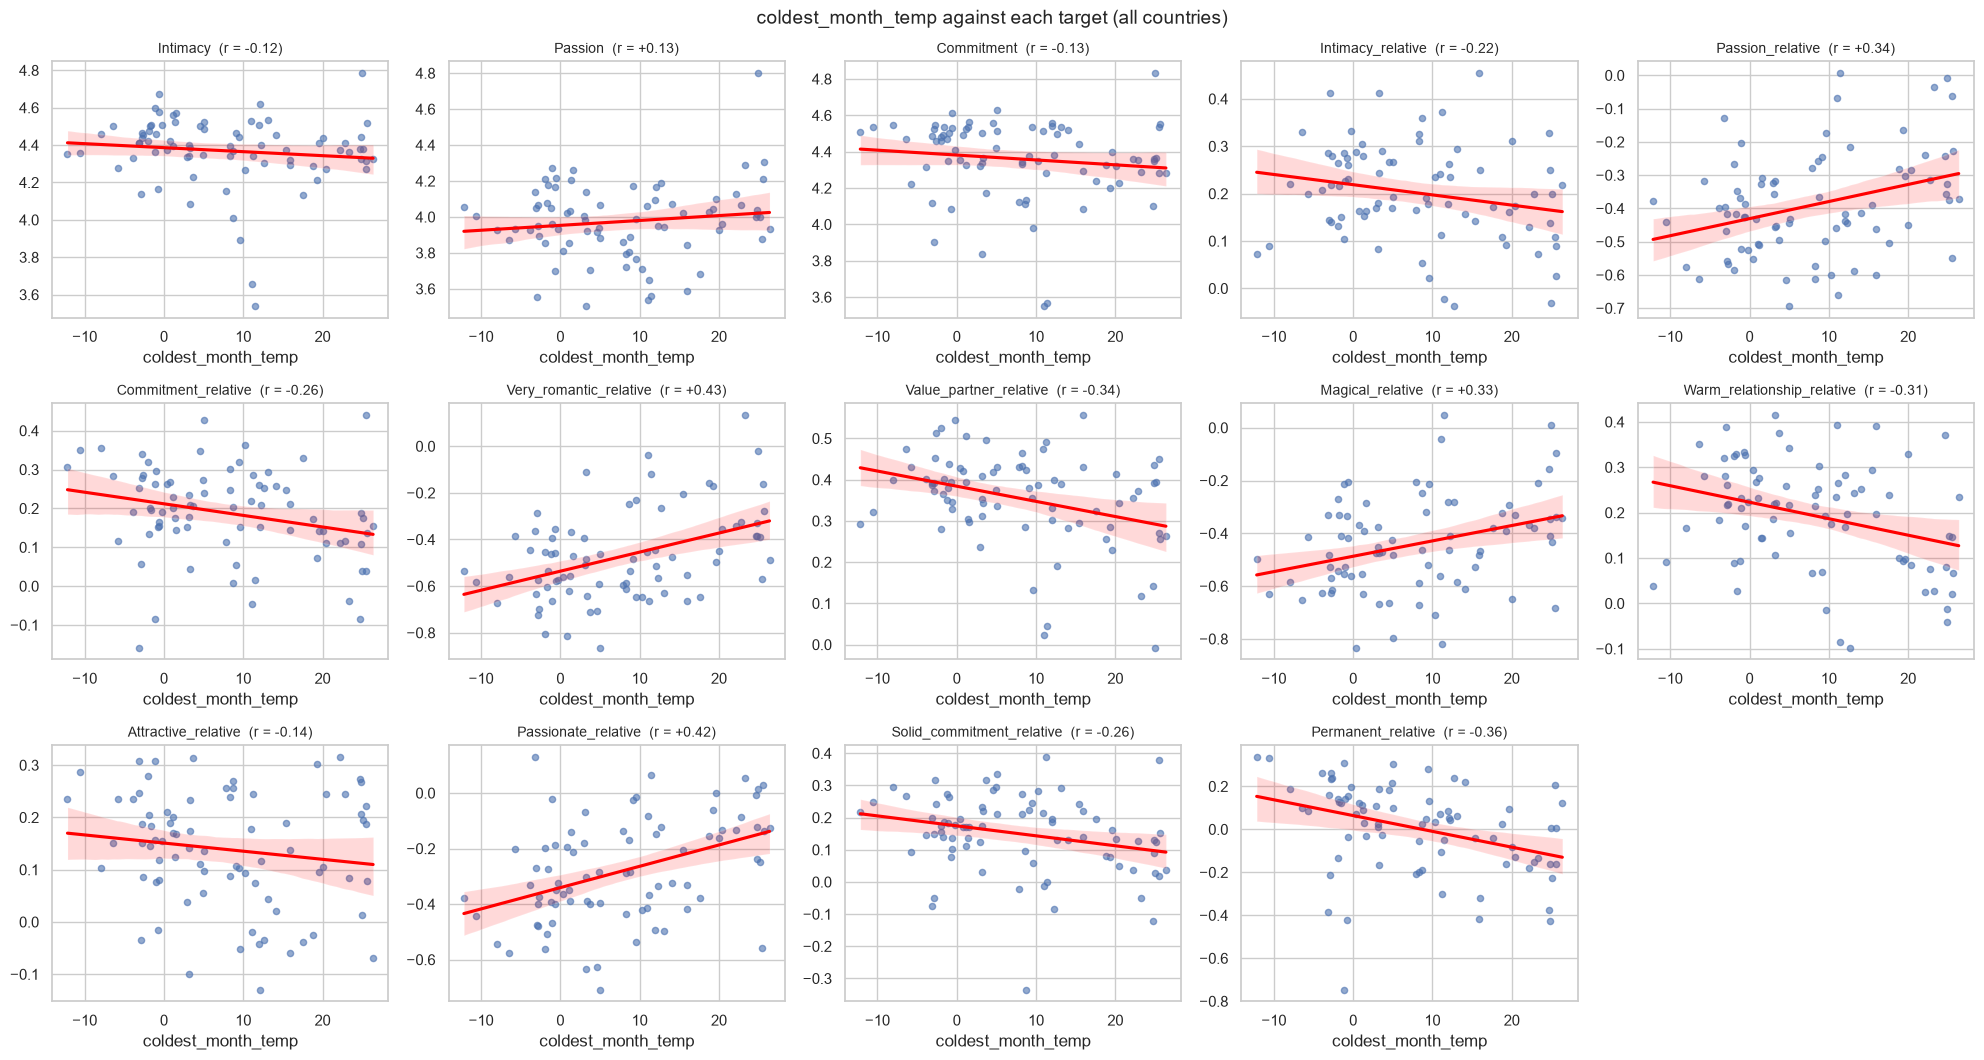

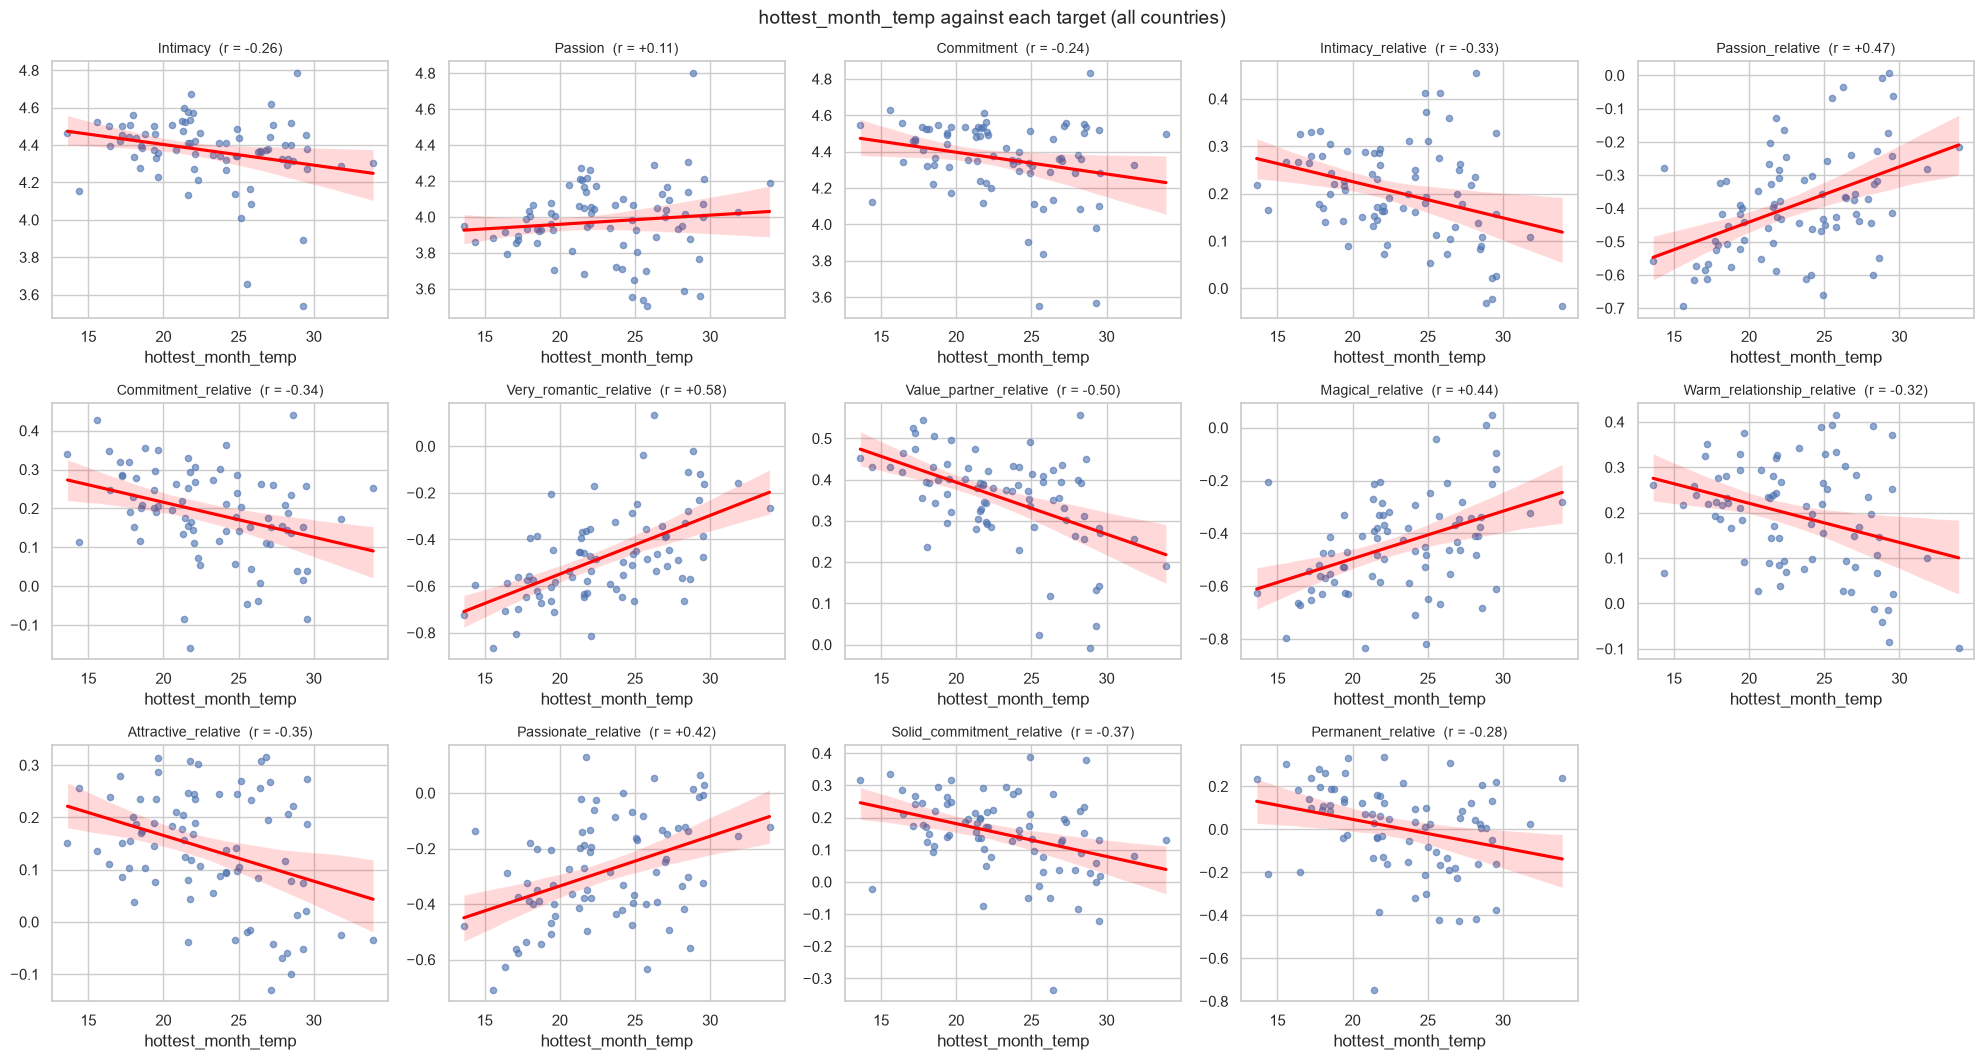

In [32]:
N_COLS = 5
n_rows = int(np.ceil(len(TARGETS) / N_COLS))
for feat in FEATURES:
    fig, axes = plt.subplots(n_rows, N_COLS, figsize=(4 * N_COLS, 3.6 * n_rows), squeeze=False)
    for ax, target in zip(axes.ravel(), TARGETS):
        sns.regplot(data=analysis_df, x=feat, y=target, ax=ax, scatter_kws={"alpha": 0.6, "s": 20}, line_kws={"color": "red"})
        ax.set_title(f"{target}  (r = {analysis_df[feat].corr(analysis_df[target]):+.2f})", fontsize=10)
        ax.set_ylabel("")
    for ax in axes.ravel()[len(TARGETS):]:
        ax.axis("off")
    fig.suptitle(f"{feat} against each target (all countries)", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"fig_scatterplots_{feat}.png", dpi=200)
    plt.show()

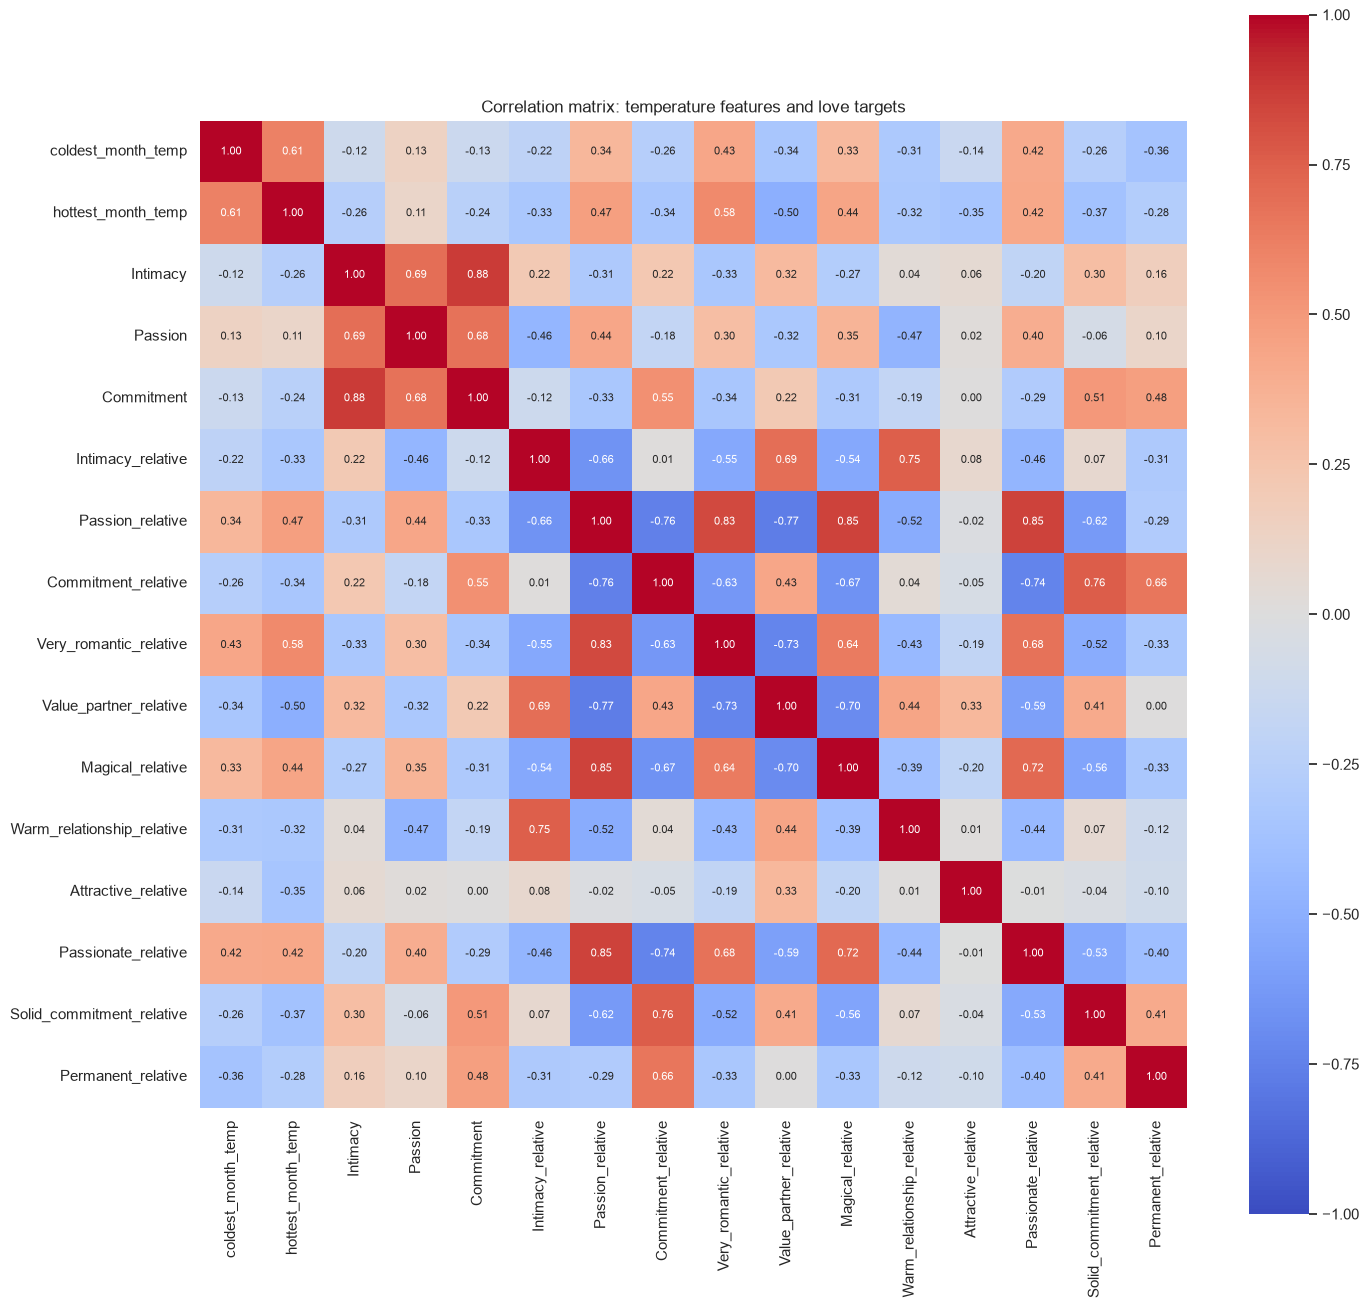

In [33]:
corr_matrix = analysis_df[FEATURES + TARGETS].corr()

size = 4 + 0.6 * len(corr_matrix)
plt.figure(figsize=(size + 1, size))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f", square=True, annot_kws={"size": 8})
plt.title("Correlation matrix: temperature features and love targets")
plt.tight_layout()
plt.savefig("fig_correlation_matrix.png", dpi=200)
plt.show()

In [34]:
rows = []
for target in TARGETS:
    row = {"target": target, "group": TARGET_GROUP[target]}
    for feat in FEATURES:
        r, p = stats.pearsonr(analysis_df[feat], analysis_df[target])
        row[f"r_{feat}"] = r
        row[f"p_{feat}"] = p
    rows.append(row)
corr_table = pd.DataFrame(rows).set_index("target")
corr_table.round(4)

,group,r_coldest_month_temp,p_coldest_month_temp,r_hottest_month_temp,p_hottest_month_temp
target,,,,,
Intimacy,raw score,-0.1156,0.3103,-0.2588,0.0213
Passion,raw score,0.1344,0.2375,0.1092,0.3379
Commitment,raw score,-0.1266,0.2663,-0.2437,0.0304
Intimacy_relative,relative score,-0.2168,0.0549,-0.3327,0.0027
Passion_relative,relative score,0.3374,0.0024,0.4727,0.0000
Commitment_relative,relative score,-0.2608,0.0203,-0.3403,0.0021
Very_romantic_relative,relative item,0.4333,0.0001,0.5777,0.0000
Value_partner_relative,relative item,-0.3377,0.0023,-0.5004,0.0000
Magical_relative,relative item,0.3281,0.0032,0.4393,0.0001


## 11. Models

Two methods, both with squared-error loss:
- **Linear Regression** 
- **Random Forest** (Each leaf holds at least 5 countries, to limit overfitting on a small sample.)

In [35]:
def make_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    }
MODEL_NAMES = list(make_models())

## 12. Training and validation errors

5-fold cross-validation on the training countries, repeated 10 times with different fold assignments, because a single split of about 60
countries gives unstable numbers. Both models see exactly the same folds.

- `train_MSE` and `val_MSE`: mean squared error on the training folds and on the held-out folds.
- `val_R2`: R2 of the held-out predictions.

In [36]:
N_SPLITS, N_REPEATS = 5, 10
rkf = RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

rows = []
for target in TARGETS:
    y_train = train_df[target].values
    train_mse = {m: [] for m in MODEL_NAMES}
    val_pred = {m: np.zeros((N_REPEATS, len(y_train))) for m in MODEL_NAMES}     # held-out prediction for every country, per repeat
    for k, (tr, va) in enumerate(rkf.split(X_train)):
        for name, model in make_models().items():
            model.fit(X_train[tr], y_train[tr])
            train_mse[name].append(mean_squared_error(y_train[tr], model.predict(X_train[tr])))
            val_pred[name][k // N_SPLITS, va] = model.predict(X_train[va])
    for name in MODEL_NAMES:
        val_mse = [mean_squared_error(y_train, p) for p in val_pred[name]]
        val_r2 = [r2_score(y_train, p) for p in val_pred[name]]
        rows.append({"target": target, "group": TARGET_GROUP[target], "model": name, "train_MSE": np.mean(train_mse[name]),
                     "val_MSE": np.mean(val_mse), "val_MSE_sd": np.std(val_mse), "val_R2": np.mean(val_r2), "val_R2_sd": np.std(val_r2)})
val_results = pd.DataFrame(rows)
val_results.round(4)

,target,group,model,train_MSE,val_MSE,val_MSE_sd,val_R2,val_R2_sd
0,Intimacy,raw score,Linear Regression,0.0276,0.0312,0.0008,-0.0251,0.0270
1,Intimacy,raw score,Random Forest,0.0200,0.0319,0.0015,-0.0471,0.0496
2,Passion,raw score,Linear Regression,0.0433,0.0484,0.0014,-0.0647,0.0307
3,Passion,raw score,Random Forest,0.0247,0.0415,0.0023,0.0863,0.0508
4,Commitment,raw score,Linear Regression,0.0382,0.0441,0.0015,-0.0754,0.0371
5,Commitment,raw score,Random Forest,0.0278,0.0475,0.0017,-0.1568,0.0417
6,Intimacy_relative,relative score,Linear Regression,0.0089,0.0101,0.0007,0.0201,0.0715
7,Intimacy_relative,relative score,Random Forest,0.0053,0.0094,0.0004,0.0891,0.0421
8,Passion_relative,relative score,Linear Regression,0.0197,0.0223,0.0010,0.0943,0.0393
9,Passion_relative,relative score,Random Forest,0.0125,0.0206,0.0015,0.1645,0.0626


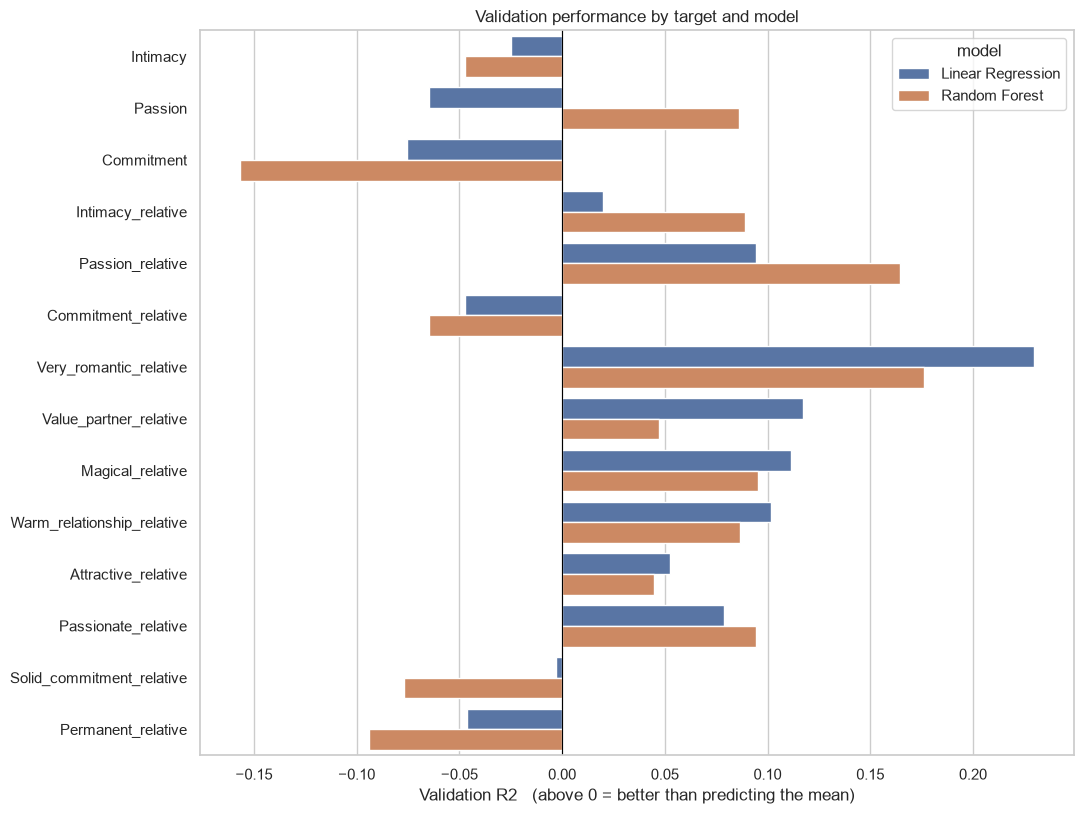

In [37]:
plt.figure(figsize=(11, 2 + 0.45 * len(TARGETS)))
ax = sns.barplot(data=val_results, y="target", x="val_R2", hue="model", order=TARGETS)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Validation R2   (above 0 = better than predicting the mean)")
ax.set_ylabel("")
ax.set_title("Validation performance by target and model")
plt.tight_layout()
plt.savefig("fig_validation_r2.png", dpi=200)
plt.show()

### Model selection

For each target, the model with the lower validation MSE is selected.

In [38]:
selected = val_results.loc[val_results.groupby("target")["val_MSE"].idxmin()].set_index("target").loc[TARGETS]
selected[["group", "model", "train_MSE", "val_MSE", "val_R2"]].round(4)

,group,model,train_MSE,val_MSE,val_R2
target,,,,,
Intimacy,raw score,Linear Regression,0.0276,0.0312,-0.0251
Passion,raw score,Random Forest,0.0247,0.0415,0.0863
Commitment,raw score,Linear Regression,0.0382,0.0441,-0.0754
Intimacy_relative,relative score,Random Forest,0.0053,0.0094,0.0891
Passion_relative,relative score,Random Forest,0.0125,0.0206,0.1645
Commitment_relative,relative score,Linear Regression,0.0114,0.0132,-0.0473
Very_romantic_relative,relative item,Linear Regression,0.0234,0.0270,0.2298
Value_partner_relative,relative item,Linear Regression,0.0086,0.0097,0.1173
Magical_relative,relative item,Linear Regression,0.0254,0.0288,0.1116


## 13. Final Results

The selected model for each target is refitted on all training countries and evaluated once on the 16 test countries. A result is convincing only when the validation and the test R2 agree.

In [39]:
rows, test_pred = [], {}
for target in TARGETS:
    name = selected.loc[target, "model"]
    y_train, y_test = train_df[target].values, test_df[target].values
    model = make_models()[name].fit(X_train, y_train)
    test_pred[target] = model.predict(X_test)
    rows.append({"target": target, "group": TARGET_GROUP[target], "selected_model": name,
                 "train_MSE": mean_squared_error(y_train, model.predict(X_train)),
                 "val_MSE": selected.loc[target, "val_MSE"],
                 "test_MSE": mean_squared_error(y_test, test_pred[target]),
                 "val_R2": selected.loc[target, "val_R2"],
                 "test_R2": r2_score(y_test, test_pred[target])})
final_results = pd.DataFrame(rows).set_index("target")
final_results.to_csv("final_results.csv")
final_results.round(4)

,group,selected_model,train_MSE,val_MSE,test_MSE,val_R2,test_R2
target,,,,,,,
Intimacy,raw score,Linear Regression,0.0279,0.0312,0.0523,-0.0251,0.0305
Passion,raw score,Random Forest,0.0243,0.0415,0.0271,0.0863,-0.0467
Commitment,raw score,Linear Regression,0.0387,0.0441,0.0649,-0.0754,0.0350
Intimacy_relative,relative score,Random Forest,0.0048,0.0094,0.0143,0.0891,-0.6583
Passion_relative,relative score,Random Forest,0.0111,0.0206,0.0256,0.1645,-0.3162
Commitment_relative,relative score,Linear Regression,0.0116,0.0132,0.0131,-0.0473,0.2154
Very_romantic_relative,relative item,Linear Regression,0.0238,0.0270,0.0261,0.2298,0.3721
Value_partner_relative,relative item,Linear Regression,0.0087,0.0097,0.0111,0.1173,0.3530
Magical_relative,relative item,Linear Regression,0.0257,0.0288,0.0268,0.1116,0.1661


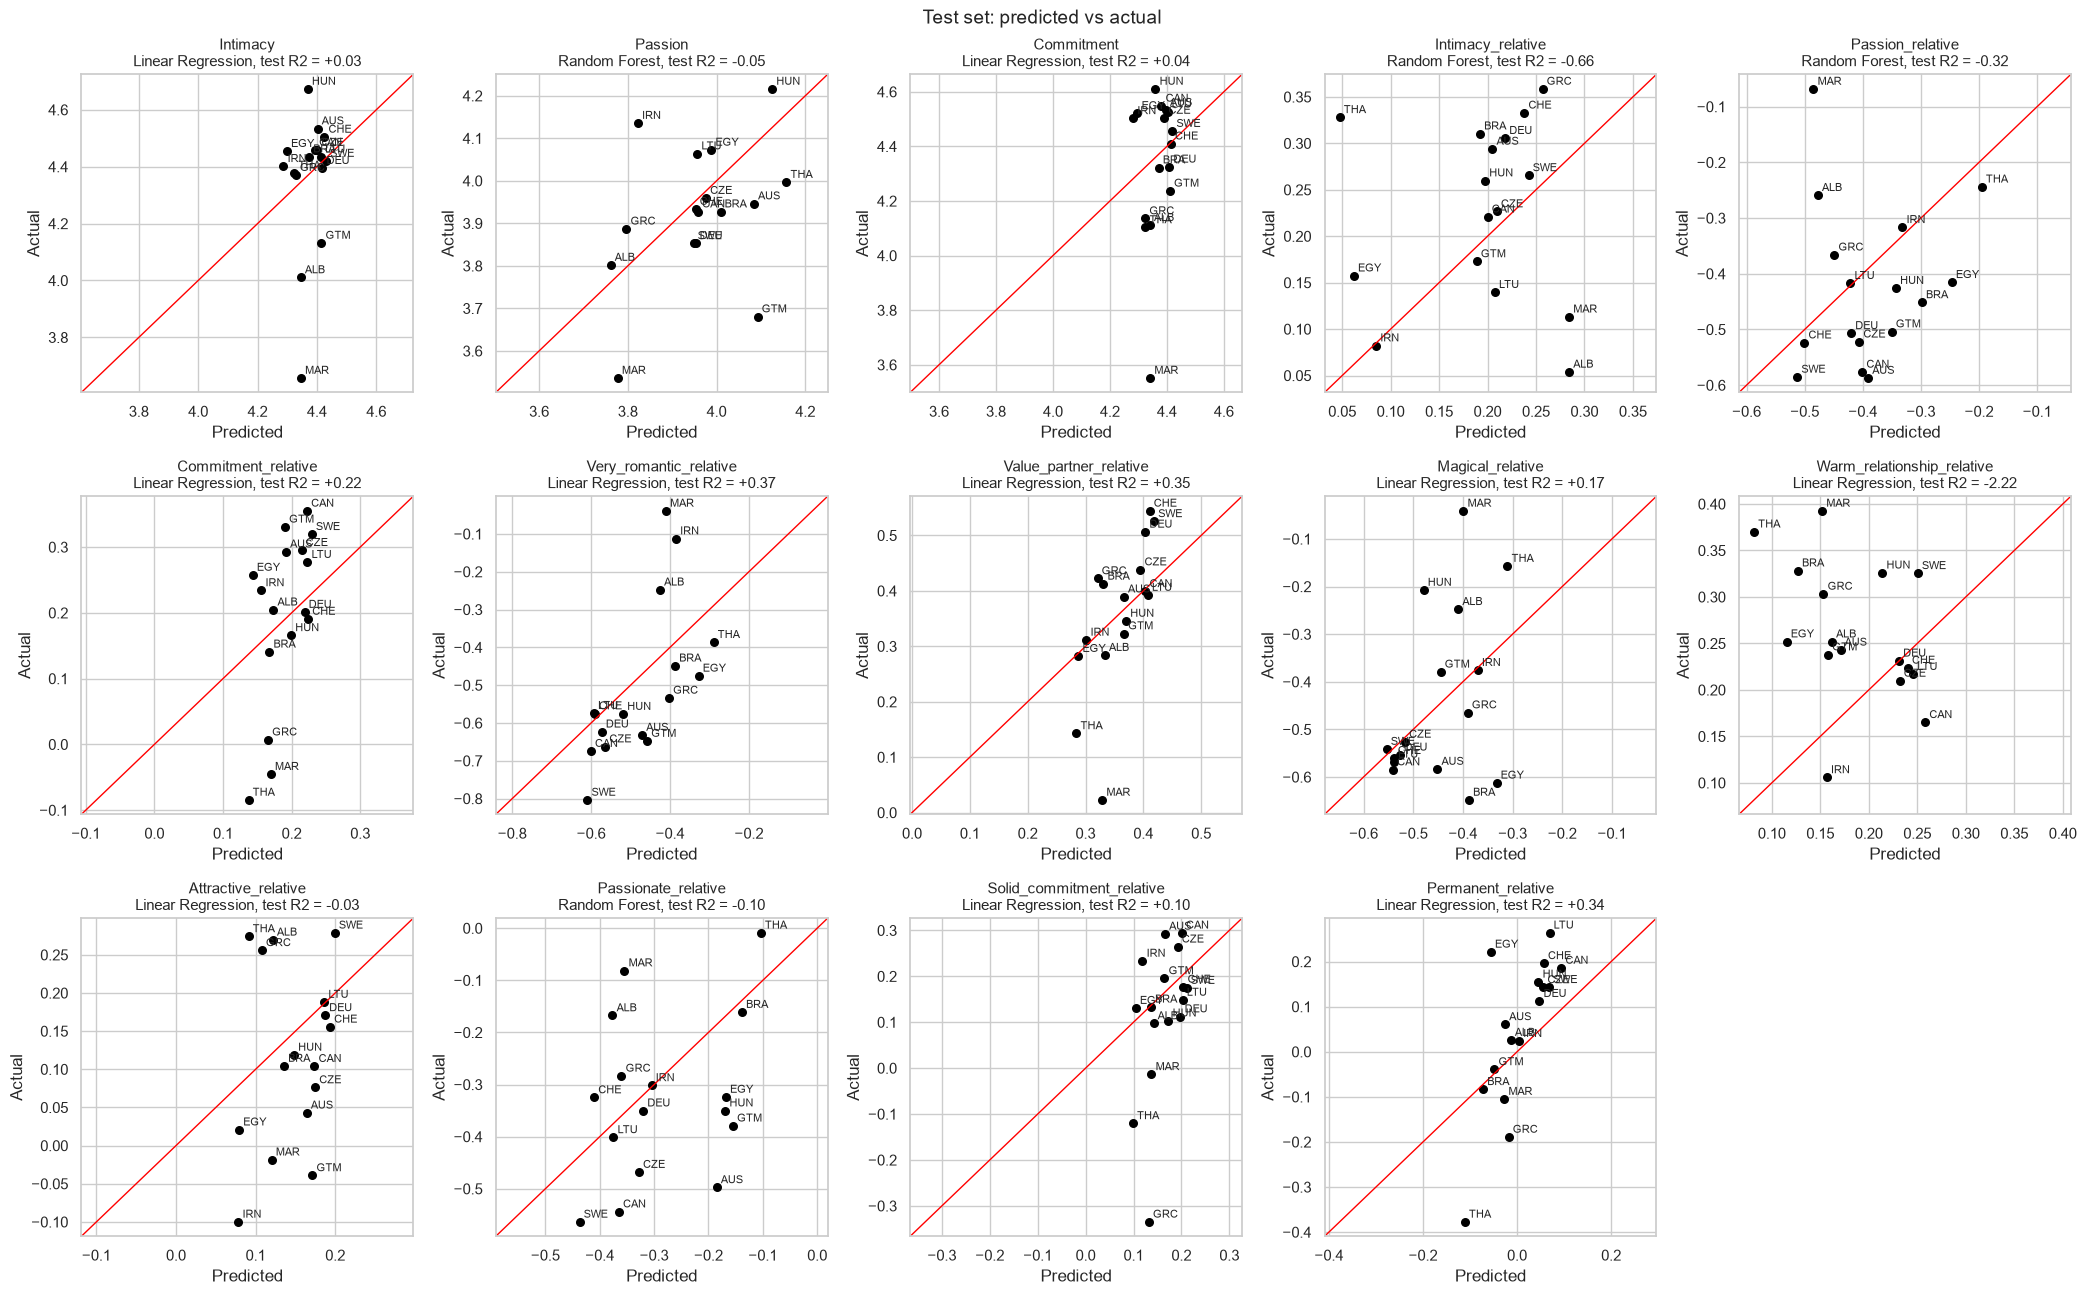

In [40]:
N_COLS = 5
n_rows = int(np.ceil(len(TARGETS) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(4.2 * N_COLS, 4.4 * n_rows), squeeze=False)
axes = axes.ravel()
for ax, target in zip(axes, TARGETS):
    pred, actual = test_pred[target], test_df[target].values
    ax.scatter(pred, actual, color="black", s=30)
    for iso, x, y in zip(test_df["iso3"], pred, actual):
        ax.annotate(iso, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
    pad = 0.05 * (max(pred.max(), actual.max()) - min(pred.min(), actual.min()))
    lims = [min(pred.min(), actual.min()) - pad, max(pred.max(), actual.max()) + pad]
    ax.plot(lims, lims, color="red", lw=1)                  # points on this line are predicted exactly
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(f"{target}\n{final_results.loc[target, 'selected_model']}, test R2 = {final_results.loc[target, 'test_R2']:+.2f}", fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in axes[len(TARGETS):]:
    ax.axis("off")
fig.suptitle("Test set: predicted vs actual", fontsize=14)
plt.tight_layout()
plt.savefig("fig_test_predictions.png", dpi=200)
plt.show()